In [1]:
#  RMS NORMALIZATION (RMSNorm)
# ============================================================

# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler



In [2]:
tf.keras.utils.set_random_seed(42)

# 2. Create RMSNorm Layer
class RMSNorm(tf.keras.layers.Layer):

    def __init__(self, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):

        features = input_shape[-1]

        self.scale = self.add_weight(
            name="scale",
            shape=(features,),
            initializer="ones",
            trainable=True
        )

    def call(self, inputs):

        mean_square = tf.reduce_mean(
            tf.square(inputs),
            axis=-1,
            keepdims=True
        )

        inverse_rms = tf.math.rsqrt(
            mean_square + self.epsilon
        )

        return inputs * inverse_rms * self.scale

    def get_config(self):

        config = super().get_config()
        config.update({"epsilon": self.epsilon})

        return config

# 3. Test RMSNorm
sample_values = tf.constant(
    [[1.0, 2.0, 3.0],
     [4.0, 5.0, 6.0]],
    dtype=tf.float32
)

rms_layer = RMSNorm()
normalized_values = rms_layer(sample_values)

print("Original Values:")
print(sample_values.numpy())

print("\nRMSNorm Values:")
print(normalized_values.numpy())

output_rms = tf.sqrt(
    tf.reduce_mean(
        tf.square(normalized_values),
        axis=-1
    )
)

print("\nOutput RMS per sample:")
print(output_rms.numpy())

# 4. Create Dataset
X, y = make_moons(
    n_samples=3000,
    noise=0.25,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



Original Values:
[[1. 2. 3.]
 [4. 5. 6.]]

RMSNorm Values:
[[0.46291    0.92582    1.38873   ]
 [0.78954196 0.98692745 1.1843129 ]]

Output RMS per sample:
[0.9999999 0.9999999]


In [4]:
# 5. Scale Features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype("float32")
X_test = scaler.transform(X_test).astype("float32")

y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

# 6. Build Model
def build_model(use_rms_norm=False):

    layers = [
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(
            64,
            use_bias=not use_rms_norm
        )
    ]

    if use_rms_norm:
        layers.append(RMSNorm())

    layers.extend([
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model = tf.keras.Sequential(layers)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

# 7. Train and Compare
histories = {}
results = {}

for use_norm in [False, True]:

    name = (
        "With RMSNorm"
        if use_norm
        else "Without RMSNorm"
    )

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(use_rms_norm=use_norm)

    print("\nTraining:", name)

    history = model.fit(
        X_train,
        y_train,
        validation_split=0.2,
        epochs=40,
        batch_size=32,
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    histories[name] = history.history

    results[name] = {
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    }

    print("Test Loss:", round(test_loss, 4))
    print("Test Accuracy:", round(test_accuracy, 4))




Training: Without RMSNorm
Epoch 1/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8198 - loss: 0.4890 - val_accuracy: 0.8396 - val_loss: 0.3728
Epoch 2/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8583 - loss: 0.3193 - val_accuracy: 0.8500 - val_loss: 0.3310
Epoch 3/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8594 - loss: 0.3033 - val_accuracy: 0.8562 - val_loss: 0.3148
Epoch 4/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8672 - loss: 0.2893 - val_accuracy: 0.8667 - val_loss: 0.2960
Epoch 5/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8766 - loss: 0.2731 - val_accuracy: 0.8771 - val_loss: 0.2742
Epoch 6/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8911 - loss: 0.2546 - val_accuracy: 0.8833 - val_loss: 0.2502
Epoch 7/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9047 - loss: 0.2354 - val_accuracy: 0.8938 - val_loss: 0.2265
Epoch 8/40
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9125 - loss: 0.2176 - val_a


RMSNorm Comparison:
                 Test Loss  Test Accuracy
Without RMSNorm   0.145005       0.946667
With RMSNorm      0.320684       0.871667


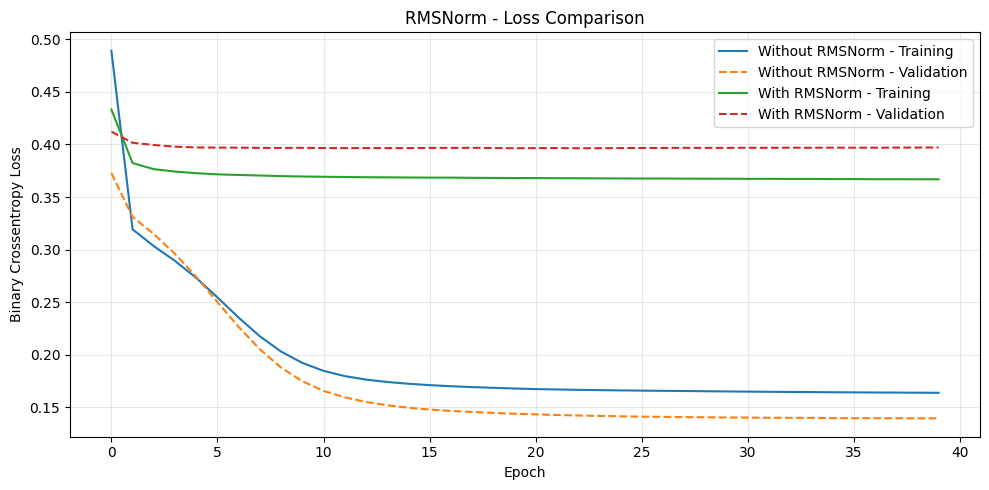

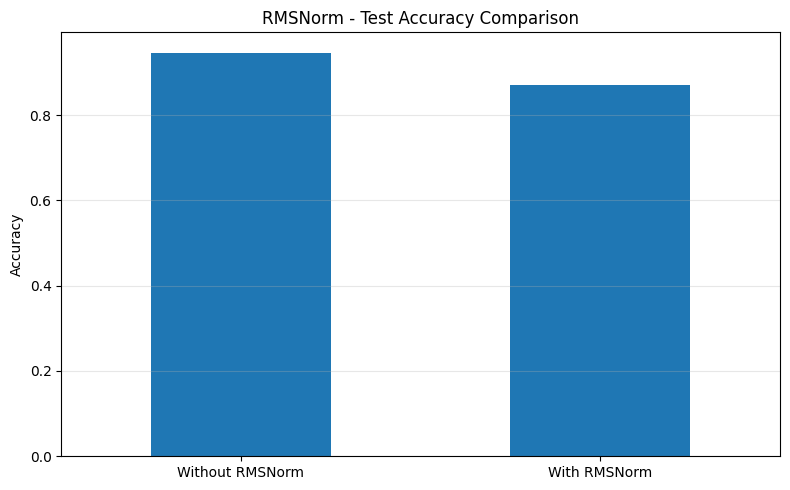

In [5]:
# 8. Display Results
results_df = pd.DataFrame(results).T
print("\nRMSNorm Comparison:")
print(results_df)

# 9. Plot Loss
plt.figure(figsize=(10, 5))

for name, history in histories.items():

    plt.plot(
        history["loss"],
        label=f"{name} - Training"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("RMSNorm - Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()




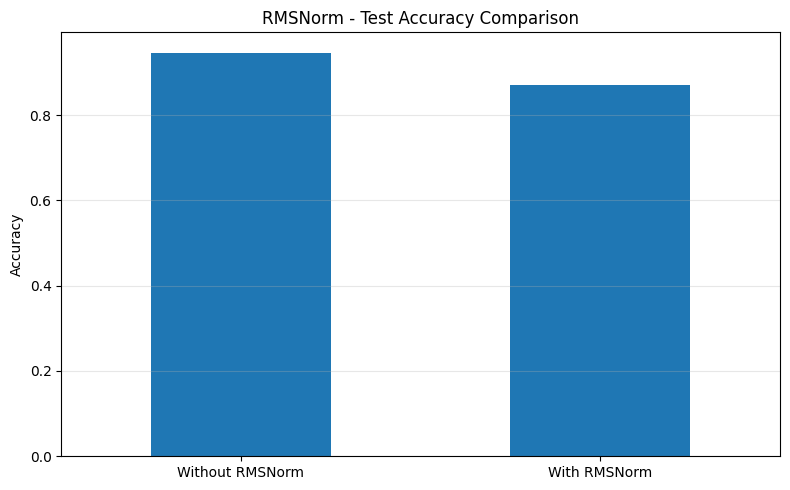

In [6]:
# 10. Plot Test Accuracy
results_df["Test Accuracy"].plot(
    kind="bar",
    figsize=(8, 5),
    title="RMSNorm - Test Accuracy Comparison"
)

plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()